In [ ]:
# Provided
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
LOCAL_PATH = "train.csv"
RANDOM_STATE = 42


def load_titanic():
    try:
        return pd.read_csv(DATA_URL)
    except Exception:
        return pd.read_csv(LOCAL_PATH)

In [ ]:
df = load_titanic()

print(f"Shape: {df.shape}")
df.info()
display(df.head())
display(df.describe().round(2))

Shape: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,1,1,"Allen, Mr. Frank",male,22.0,0,0,PC 95786,36.30,C89,C
1,2,1,1,"Collins, Miss. Helen",female,22.0,0,1,182735,246.29,D113,C
2,3,1,3,"Reed, Mrs. Helen",female,NaN,0,0,C.A. 39697,7.54,NaN,S
3,4,1,2,"Bennett, Mr. Thomas",male,NaN,4,0,216405,6.71,NaN,S
4,5,0,3,"Green, Mr. John",male,NaN,0,0,137836,9.89,D62,S


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,25.88,0.47,0.39,29.25
std,257.35,0.49,0.84,13.99,0.98,0.83,48.97
min,1.00,0.00,1.00,1.00,0.00,0.00,1.79
25%,223.50,0.00,2.00,16.00,0.00,0.00,7.12
50%,446.00,0.00,3.00,25.00,0.00,0.00,11.93
75%,668.50,1.00,3.00,36.00,1.00,0.00,25.90
max,891.00,1.00,3.00,75.00,8.00,6.00,492.38


In [ ]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(1),
})
missing_summary = missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_pct", ascending=False)
display(missing_summary)

print(f"Duplicated rows: {df.duplicated().sum()}")
print(f"PassengerId unique: {df['PassengerId'].is_unique}")

,missing_count,missing_pct
Cabin,687,77.1
Age,177,19.9
Embarked,2,0.2


Duplicated rows: 0
PassengerId unique: True


In [ ]:
print(df["Survived"].value_counts(normalize=True).round(3))

for col in ["Sex", "Pclass", "Embarked"]:
    print(f"\n{col}")
    display(df.groupby(col)["Survived"].agg(survival_rate="mean", passengers="size").round(3))

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64

Sex


,survival_rate,passengers
Sex,,
female,0.742,314
male,0.189,577


,survival_rate,passengers
Pclass,,
1,0.630,216
2,0.473,184
3,0.242,491


,survival_rate,passengers
Embarked,,
C,0.503,157
Q,0.371,70
S,0.355,662


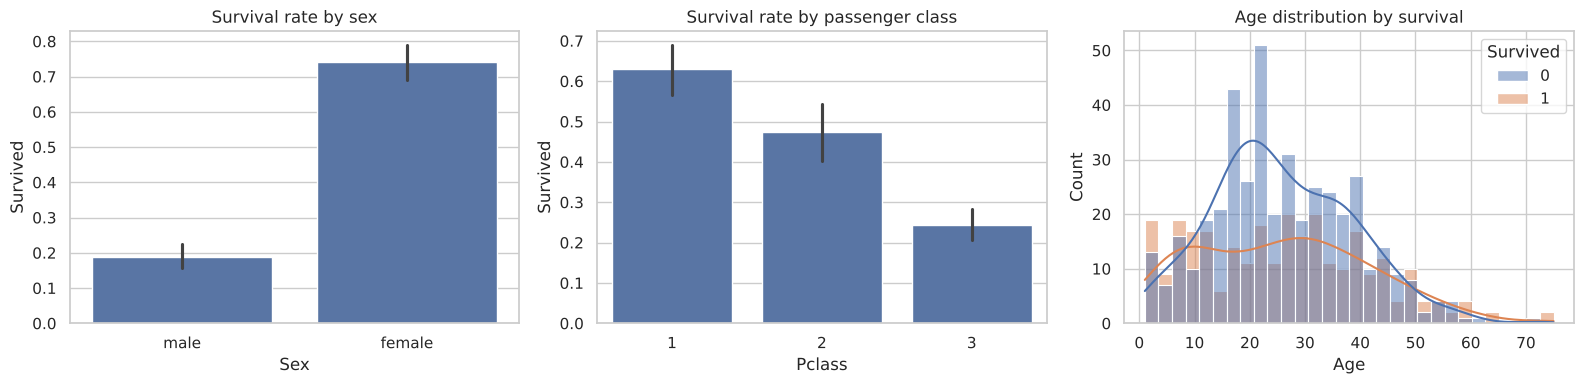

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0])
axes[0].set_title("Survival rate by sex")

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1])
axes[1].set_title("Survival rate by passenger class")

sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, ax=axes[2])
axes[2].set_title("Age distribution by survival")

plt.tight_layout()
plt.show()

Pclass,1,2,3
Sex,,,
female,94,76,144
male,122,108,347


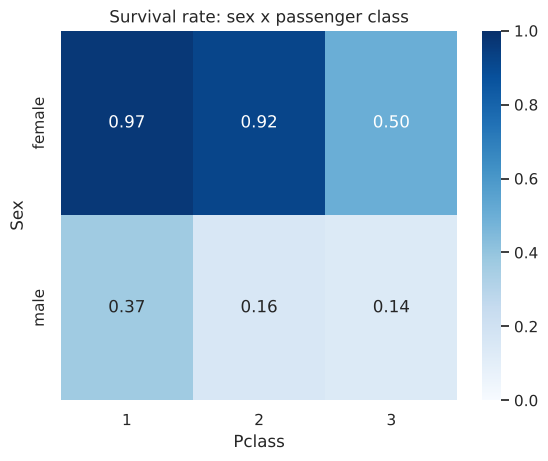

In [ ]:
rate_pivot = df.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="mean")
count_pivot = df.pivot_table(values="Survived", index="Sex", columns="Pclass", aggfunc="size")

sns.heatmap(rate_pivot, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1)
plt.title("Survival rate: sex x passenger class")
plt.show()

display(count_pivot)

In [ ]:
X = df.drop(columns="Survived")
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Survival rate - train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Train: (712, 11) | Test: (179, 11)
Survival rate - train: 0.383 | test: 0.385


In [ ]:
def preprocess(frame, age_median, embarked_mode):
    out = frame.copy()

    out["Age"] = out["Age"].fillna(age_median)
    out["Embarked"] = out["Embarked"].fillna(embarked_mode)

    out["FamilySize"] = out["SibSp"] + out["Parch"] + 1
    out["IsAlone"] = (out["FamilySize"] == 1).astype(int)

    out["Sex"] = out["Sex"].map({"male": 0, "female": 1})

    out["Embarked"] = pd.Categorical(out["Embarked"], categories=["C", "Q", "S"])
    out = pd.get_dummies(out, columns=["Embarked"], drop_first=True, dtype=int)

    return out.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

In [ ]:
age_median = X_train["Age"].median()
embarked_mode = X_train["Embarked"].mode()[0]

X_train_p = preprocess(X_train, age_median, embarked_mode)
X_test_p = preprocess(X_test, age_median, embarked_mode)

assert X_train_p.isna().sum().sum() == 0 and X_test_p.isna().sum().sum() == 0
assert list(X_train_p.columns) == list(X_test_p.columns)
assert all(pd.api.types.is_numeric_dtype(t) for t in X_train_p.dtypes)

print(f"age_median = {age_median} | embarked_mode = {embarked_mode}")
print(list(X_train_p.columns))
X_train_p.head()

age_median = 25.0 | embarked_mode = S
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'Embarked_Q', 'Embarked_S']


,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,IsAlone,Embarked_Q,Embarked_S
670,3,0,25.0,1,1,13.36,3,0,1,0
492,3,1,25.0,0,0,3.09,1,1,0,1
539,3,0,25.0,0,0,6.21,1,1,0,0
827,2,1,22.0,0,0,19.01,1,1,0,0
768,3,1,2.0,1,0,4.47,2,0,0,1


In [ ]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te):
    pred = model.predict(X_te)
    return {
        "train_acc": accuracy_score(y_tr, model.predict(X_tr)),
        "test_acc": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred),
        "f1": f1_score(y_te, pred, zero_division=0),
    }

In [ ]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train_p, y_train)

scores = {}
scores["Baseline"] = evaluate_model(baseline, X_train_p, y_train, X_test_p, y_test)
print({k: round(v, 3) for k, v in scores["Baseline"].items()})

{'train_acc': 0.617, 'test_acc': 0.615, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


{'train_acc': 0.789, 'test_acc': 0.777, 'precision': 0.716, 'recall': 0.696, 'f1': 0.706}
              precision    recall  f1-score   support

        Died       0.81      0.83      0.82       110
    Survived       0.72      0.70      0.71        69

    accuracy                           0.78       179
   macro avg       0.76      0.76      0.76       179
weighted avg       0.78      0.78      0.78       179



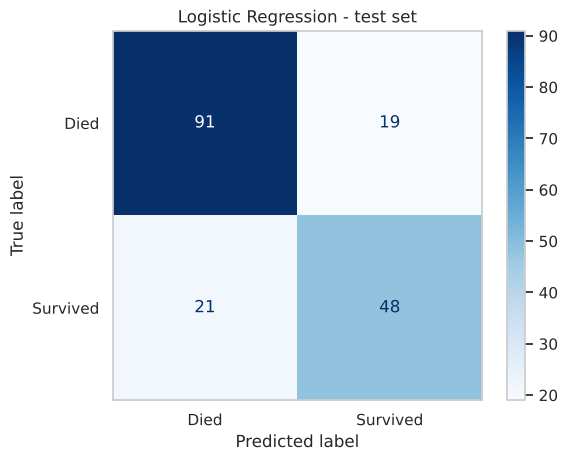

In [ ]:
log_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(X_train_p, y_train)
scores["Logistic Regression"] = evaluate_model(log_model, X_train_p, y_train, X_test_p, y_test)
print({k: round(v, 3) for k, v in scores["Logistic Regression"].items()})

ConfusionMatrixDisplay.from_estimator(log_model, X_test_p, y_test,
                                      display_labels=["Died", "Survived"], cmap="Blues")
plt.title("Logistic Regression - test set")
plt.grid(False)
plt.show()

print(classification_report(y_test, log_model.predict(X_test_p), target_names=["Died", "Survived"]))

In [ ]:
odds_ratios = pd.Series(np.exp(log_model.coef_[0]), index=X_train_p.columns).sort_values(ascending=False)
odds_ratios.round(3)

Sex           12.824
Embarked_Q     1.620
Fare           1.002
Parch          0.991
Age            0.982
FamilySize     0.910
SibSp          0.906
IsAlone        0.785
Embarked_S     0.753
Pclass         0.346
dtype: float64

{'train_acc': 1.0, 'test_acc': 0.804, 'precision': 0.774, 'recall': 0.696, 'f1': 0.733}


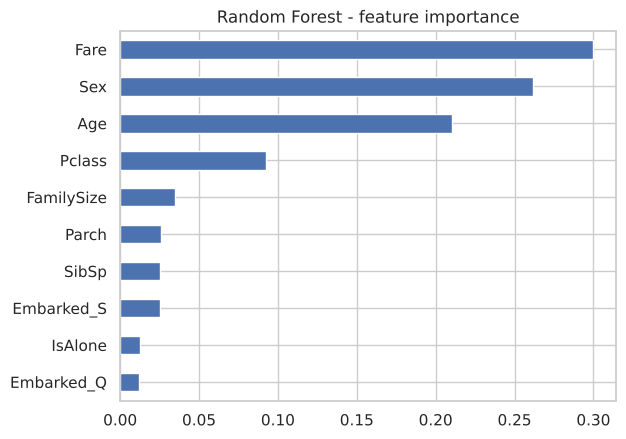

In [ ]:
rf_model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_train_p, y_train)
scores["Random Forest"] = evaluate_model(rf_model, X_train_p, y_train, X_test_p, y_test)
print({k: round(v, 3) for k, v in scores["Random Forest"].items()})

importances = pd.Series(rf_model.feature_importances_, index=X_train_p.columns).sort_values()
importances.plot.barh(title="Random Forest - feature importance")
plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
models = {"Baseline": baseline, "Logistic Regression": log_model, "Random Forest": rf_model}

cv_summary = {}
for name, model in models.items():
    fold_scores = cross_val_score(model, X_train_p, y_train, cv=cv, scoring="accuracy")
    cv_summary[name] = {"cv_mean": fold_scores.mean(), "cv_std": fold_scores.std()}
    print(f"{name:<22} mean = {fold_scores.mean():.3f} | std = {fold_scores.std():.3f}")

Baseline               mean = 0.617 | std = 0.003
Logistic Regression    mean = 0.770 | std = 0.024
Random Forest          mean = 0.782 | std = 0.019


In [ ]:
results = pd.DataFrame(scores).T.join(pd.DataFrame(cv_summary).T).round(3).sort_values("cv_mean", ascending=False)
results

,train_acc,test_acc,precision,recall,f1,cv_mean,cv_std
Random Forest,1.000,0.804,0.774,0.696,0.733,0.782,0.019
Logistic Regression,0.789,0.777,0.716,0.696,0.706,0.770,0.024
Baseline,0.617,0.615,0.000,0.000,0.000,0.617,0.003
